# Bài thực hành Buổi 1 - Bài 5a Trang 45
## Online Retail - Germany

In [1]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")


Ngô Thành Khôi - 6451071038


### Câu 1: Đọc, tiền xử lý và tạo one-hot encoding cho Germany

In [2]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Đọc dữ liệu và tiền xử lý
retail = pd.read_excel("Online Retail.xlsx")
retail["Description"] = retail["Description"].astype("string").str.strip()
retail = retail.dropna(subset=["InvoiceNo"]).copy()
retail["InvoiceNo"] = retail["InvoiceNo"].astype(str)
retail = retail[~retail["InvoiceNo"].str.contains("C", na=False)].copy()

# Lọc riêng Germany
germany_retail = retail[retail["Country"] == "Germany"].copy()
basket_de = germany_retail.groupby(["InvoiceNo", "Description"])["Quantity"].sum().unstack().fillna(0)
basket_de_encoded = basket_de.map(lambda value: 1 if value >= 1 else 0)
basket_de_encoded = basket_de_encoded.drop(columns=["POSTAGE"], errors="ignore")

print("Kích thước dữ liệu Germany:", basket_de_encoded.shape)
display(basket_de_encoded.head())


Ngô Thành Khôi - 6451071038
Kích thước dữ liệu Germany: (457, 1694)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Câu 2: Tìm tập phổ biến và luật bằng Apriori

In [3]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Apriori min_support=0.05
de_apriori_items = apriori(basket_de_encoded, min_support=0.05, use_colnames=True)
de_apriori_rules = association_rules(de_apriori_items, metric="confidence", min_threshold=0.5)
de_apriori_rules = de_apriori_rules.sort_values(["confidence", "lift"], ascending=False)

print("Tập phổ biến Apriori:")
display(de_apriori_items)
print("Các luật kết hợp Apriori:")
for _, row in de_apriori_rules.iterrows():
    print(f"{set(row['antecedents'])} ==> {set(row['consequents'])} [ {row['support']:.4f} , {row['confidence']:.4f} ]")


Ngô Thành Khôi - 6451071038
Tập phổ biến Apriori:


c:\Users\Thanh Khoi\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
1,0.070022,frozenset({ALARM CLOCK BAKELIKE PINK})
2,0.065646,frozenset({CHARLOTTE BAG APPLES DESIGN})
3,0.050328,frozenset({CHILDRENS CUTLERY DOLLY GIRL})
4,0.061269,frozenset({COFFEE MUG APPLES DESIGN})
5,0.063457,frozenset({FAWN BLUE HOT WATER BOTTLE})
6,0.072210,frozenset({GUMBALL COAT RACK})
7,0.056893,frozenset({IVORY KITCHEN SCALES})
8,0.063457,frozenset({JAM JAR WITH PINK LID})
9,0.091904,frozenset({JAM MAKING SET PRINTED})


Các luật kết hợp Apriori:
{'RED RETROSPOT CHARLOTTE BAG'} ==> {'WOODLAND CHARLOTTE BAG'} [ 0.0591 , 0.8438 ]
{'ROUND SNACK BOXES SET OF 4 FRUITS'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.1313 , 0.8333 ]
{'SPACEBOY LUNCH BOX'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.0700 , 0.6809 ]
{'PLASTERS IN TIN CIRCUS PARADE'} ==> {'PLASTERS IN TIN WOODLAND ANIMALS'} [ 0.0678 , 0.5849 ]
{'PLASTERS IN TIN SPACEBOY'} ==> {'PLASTERS IN TIN WOODLAND ANIMALS'} [ 0.0613 , 0.5714 ]
{'PLASTERS IN TIN WOODLAND ANIMALS'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.0744 , 0.5397 ]
{'ROUND SNACK BOXES SET OF4 WOODLAND'} ==> {'ROUND SNACK BOXES SET OF 4 FRUITS'} [ 0.1313 , 0.5357 ]
{'WOODLAND CHARLOTTE BAG'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.0635 , 0.5000 ]


### Câu 3: FP-Growth, scatter và so sánh

Ngô Thành Khôi - 6451071038
Tập phổ biến FP-Growth:


c:\Users\Thanh Khoi\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
0,0.100656,frozenset({JUMBO BAG WOODLAND ANIMALS})
1,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
2,0.091904,frozenset({JAM MAKING SET PRINTED})
3,0.085339,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
4,0.063457,frozenset({JAM JAR WITH PINK LID})
5,0.078775,frozenset({JUMBO BAG RED RETROSPOT})
6,0.067834,frozenset({WOODLAND PARTY BAG + STICKER SET})
7,0.056893,frozenset({IVORY KITCHEN SCALES})
8,0.054705,frozenset({MEMO BOARD COTTAGE DESIGN})
9,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})


Các luật kết hợp FP-Growth:
{'RED RETROSPOT CHARLOTTE BAG'} ==> {'WOODLAND CHARLOTTE BAG'} [ 0.0591 , 0.8438 ]
{'ROUND SNACK BOXES SET OF 4 FRUITS'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.1313 , 0.8333 ]
{'SPACEBOY LUNCH BOX'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.0700 , 0.6809 ]
{'PLASTERS IN TIN CIRCUS PARADE'} ==> {'PLASTERS IN TIN WOODLAND ANIMALS'} [ 0.0678 , 0.5849 ]
{'PLASTERS IN TIN SPACEBOY'} ==> {'PLASTERS IN TIN WOODLAND ANIMALS'} [ 0.0613 , 0.5714 ]
{'PLASTERS IN TIN WOODLAND ANIMALS'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.0744 , 0.5397 ]
{'ROUND SNACK BOXES SET OF4 WOODLAND'} ==> {'ROUND SNACK BOXES SET OF 4 FRUITS'} [ 0.1313 , 0.5357 ]
{'WOODLAND CHARLOTTE BAG'} ==> {'ROUND SNACK BOXES SET OF4 WOODLAND'} [ 0.0635 , 0.5000 ]


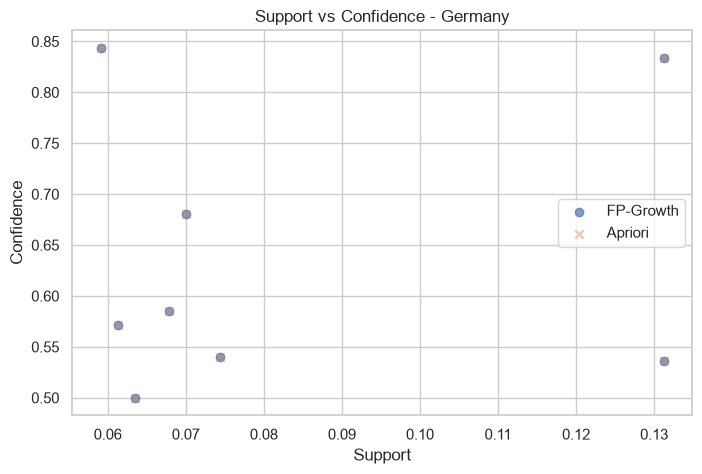

Apriori: 59 tập phổ biến, 8 luật
FP-Growth: 59 tập phổ biến, 8 luật


In [4]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# FP-Growth với cùng ngưỡng
de_fp_items = fpgrowth(basket_de_encoded, min_support=0.05, use_colnames=True)
de_fp_rules = association_rules(de_fp_items, metric="confidence", min_threshold=0.5)
de_fp_rules = de_fp_rules.sort_values(["confidence", "lift"], ascending=False)

print("Tập phổ biến FP-Growth:")
display(de_fp_items)
print("Các luật kết hợp FP-Growth:")
for _, row in de_fp_rules.iterrows():
    print(f"{set(row['antecedents'])} ==> {set(row['consequents'])} [ {row['support']:.4f} , {row['confidence']:.4f} ]")

# Scatter support-confidence
plt.figure(figsize=(8, 5))
plt.scatter(de_fp_rules["support"], de_fp_rules["confidence"], alpha=0.7, label="FP-Growth")
if len(de_apriori_rules):
    plt.scatter(de_apriori_rules["support"], de_apriori_rules["confidence"], alpha=0.45, marker="x", label="Apriori")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Support vs Confidence - Germany")
plt.legend()
plt.grid(True)
plt.show()

print("Apriori:", len(de_apriori_items), "tập phổ biến,", len(de_apriori_rules), "luật")
print("FP-Growth:", len(de_fp_items), "tập phổ biến,", len(de_fp_rules), "luật")


**Nhận xét:** Khi giữ nguyên dữ liệu và ngưỡng, Apriori và FP-Growth tạo cùng tập phổ biến và luật. Hai thuật toán có kết quả logic tương đương; FP-Growth thường tiết kiệm quét dữ liệu hơn Apriori.